<a href="https://colab.research.google.com/github/AlfredaDhaifullah04/PCVK_Ganjil_2026/blob/main/PCVK_M7_W8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MODUL 7 – Segmentasi
## Segmentasi Citra Dengan Tresholding

**Mata Kuliah:** Pengolahan Citra dan Visi Komputer  
**Nama:** [Alfreda Dhaifullah Mahezwara]  
**NIM:** [2441107020219]

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Library yang digunakan sesuai modul praktikum
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood
import os

# Membuat folder direktori sampel jika belum ada
os.makedirs('/content/sample_data/images', exist_ok=True)
print("Library berhasil diimpor!")

Library berhasil diimpor!


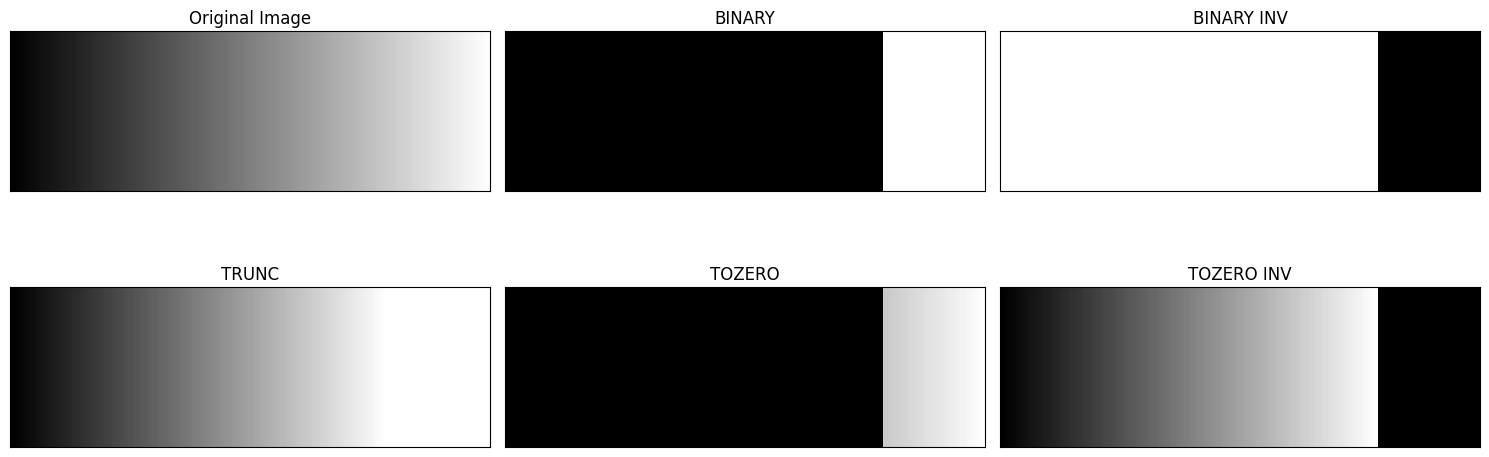

In [ ]:
# Membuat citra gradient sintetis untuk uji coba global threshold
gradient_img = np.tile(np.linspace(0, 255, 300, dtype=np.uint8), (100, 1))
thresh_val = 200
max_val = 255

# Implementasi manual berdasarkan ketentuan modul
img_binary = np.where(gradient_img > thresh_val, max_val, 0).astype(np.uint8)
img_binary_inv = np.where(gradient_img > thresh_val, 0, max_val).astype(np.uint8)
img_trunc = np.where(gradient_img > thresh_val, thresh_val, gradient_img).astype(np.uint8)
img_tozero = np.where(gradient_img > thresh_val, gradient_img, 0).astype(np.uint8)
img_tozero_inv = np.where(gradient_img > thresh_val, 0, gradient_img).astype(np.uint8)

# Plotting Hasil Visualisasi
titles = ['Original Image', 'BINARY', 'BINARY INV', 'TRUNC', 'TOZERO', 'TOZERO INV']
images = [gradient_img, img_binary, img_binary_inv, img_trunc, img_tozero, img_tozero_inv]

plt.figure(figsize=(15, 6))
for i in range(len(images)):
    plt.subplot(2, 3, i + 1)
    plt.imshow(images[i], cmap='gray', interpolation='nearest')
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()

File ‘/content/sample_data/images/sudoku.png’ already there; not retrieving.


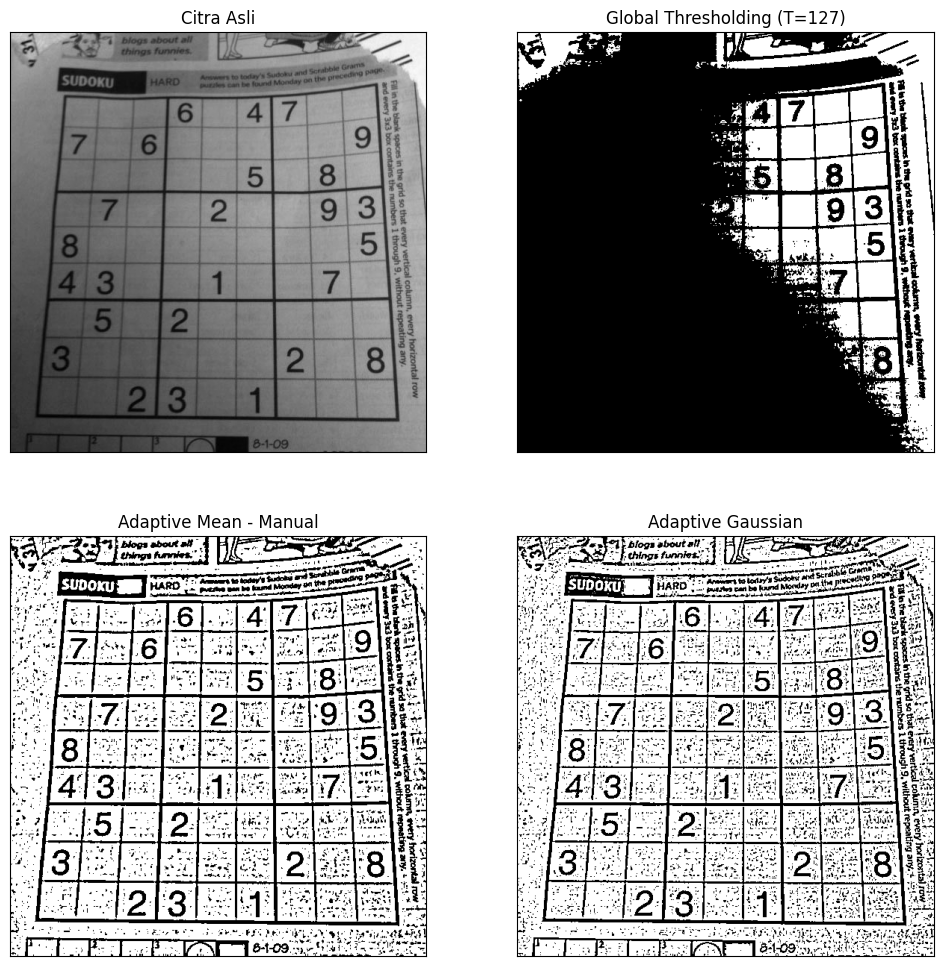

In [ ]:
# Mengunduh sampel citra sudoku otomatis
!wget -nc https://raw.githubusercontent.com/opencv/opencv/master/samples/data/sudoku.png -O /content/sample_data/images/sudoku.png

sudoku_img = cv.imread('/content/sample_data/images/sudoku.png', 0)

def manual_adaptive_mean(img, block_size, C):
    h, w = img.shape
    pad = block_size // 2
    padded = np.pad(img, pad, mode='reflect').astype(np.float32)
    out = np.zeros((h, w), dtype=np.uint8)
    integral = cv.integral(padded)

    for r in range(h):
        for c in range(w):
            # Di citra ter-pad, pixel asli (r, c) berada di (r + pad, c + pad)
            # Kotak tetangga berukuran block_size x block_size disekitarnya:
            # baris dari r sampai r + block_size, kolom dari c sampai c + block_size
            x1, y1 = c, r
            x2, y2 = c + block_size, r + block_size

            # Menggunakan rumus tabel integral standard
            sum_val = integral[y2, x2] - integral[y1, x2] - integral[y2, x1] + integral[y1, x1]
            mean_val = sum_val / (block_size * block_size)
            out[r, c] = 255 if img[r, c] > (mean_val - C) else 0
    return out

# Global threshold manual (T=127) dan adaptive mean manual
global_th = np.where(sudoku_img > 127, 255, 0).astype(np.uint8)
adaptive_mean_manual = manual_adaptive_mean(sudoku_img, 11, 2)
adaptive_gauss = cv.adaptiveThreshold(sudoku_img, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY, 11, 2)

# Tampilkan perbandingan
titles = ['Citra Asli', 'Global Thresholding (T=127)', 'Adaptive Mean - Manual', 'Adaptive Gaussian']
res_images = [sudoku_img, global_th, adaptive_mean_manual, adaptive_gauss]

plt.figure(figsize=(12, 12))
for i in range(4):
    plt.subplot(2, 2, i + 1)
    plt.imshow(res_images[i], cmap='gray')
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.show()

--2026-10-14 07:37:27--  https://raw.githubusercontent.com/opencv/opencv/master/samples/data/lena.jpg
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.110.133, 185.199.108.133, 185.199.111.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.110.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 91814 (90K) [image/jpeg]
Saving to: ‘/content/sample_data/images/lena.jpg’

/content/sample_dat 100%[===================>]  89.66K  --.-KB/s    in 0.003s  

2026-10-14 07:37:27 (29.3 MB/s) - ‘/content/sample_data/images/lena.jpg’ saved [91814/91814]



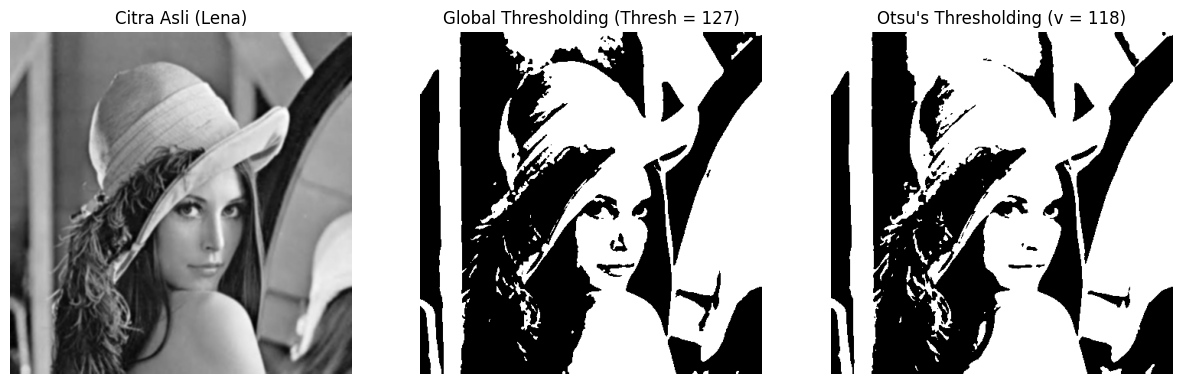

In [ ]:
# Mengunduh sampel citra Lena
!wget -nc https://raw.githubusercontent.com/opencv/opencv/master/samples/data/lena.jpg -O /content/sample_data/images/lena.jpg
lena_color = cv.imread('/content/drive/MyDrive/Colab Notebooks/semester 5/PCVk/foto /Lena.jpg')
lena_gray = cv.cvtColor(lena_color, cv.COLOR_BGR2GRAY)
lena_blur = cv.GaussianBlur(lena_gray, (5, 5), 0)

def custom_otsu(gray_img):
    pixel_number = gray_img.shape[0] * gray_img.shape[1]
    mean_weight = 1.0 / pixel_number
    his, bins = np.histogram(gray_img, bins=np.arange(0, 257))

    final_thresh = -1
    final_value = -1
    intensity_arr = np.arange(256)

    for t in bins[1:-1]:
        pcb = np.sum(his[:t])
        pcf = np.sum(his[t:])
        if pcb == 0 or pcf == 0:
            continue

        Wb = pcb * mean_weight
        Wf = pcf * mean_weight
        mub = np.sum(intensity_arr[:t] * his[:t]) / float(pcb)
        muf = np.sum(intensity_arr[t:] * his[t:]) / float(pcf)

        value = Wb * Wf * ((mub - muf) ** 2)
        if value > final_value:
            final_value = value
            final_thresh = t

    final_img = np.where(gray_img > final_thresh, 255, 0).astype(np.uint8)
    return final_img, final_thresh

otsu_biner, otsu_thresh = custom_otsu(lena_blur)
_, global_bin = cv.threshold(lena_blur, 127, 255, cv.THRESH_BINARY)

# Plotting Hasil
plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(lena_blur, cmap='gray')
plt.title('Citra Asli (Lena)')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(global_bin, cmap='gray')
plt.title('Global Thresholding (Thresh = 127)')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(otsu_biner, cmap='gray')
plt.title(f"Otsu's Thresholding (v = {otsu_thresh})")
plt.axis('off')
plt.show()

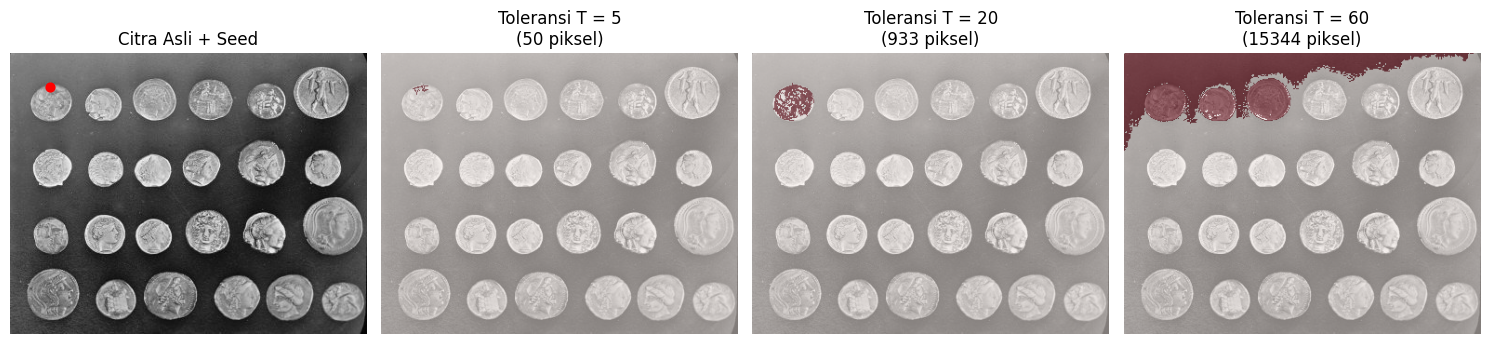

In [ ]:
coins_img = data.coins()
seed_point = (36, 43) # Koordinat baris, kolom
tolerance_list = [5, 20, 60]

plt.figure(figsize=(15, 5))
plt.subplot(1, 4, 1)
plt.imshow(coins_img, cmap='gray')
plt.scatter(seed_point[1], seed_point[0], c='red', s=40)
plt.title('Citra Asli + Seed')
plt.axis('off')

for idx, tol in enumerate(tolerance_list):
    res_flood = flood(coins_img, seed_point, tolerance=tol)
    pixel_count = np.sum(res_flood)

    plt.subplot(1, 4, idx + 2)
    plt.imshow(coins_img, cmap='gray')
    plt.imshow(res_flood, cmap='Reds', alpha=0.5)
    plt.title(f'Toleransi T = {tol}\n({pixel_count} piksel)')
    plt.axis('off')

plt.tight_layout()
plt.show()

File ‘/content/sample_data/images/lily.jpg’ already there; not retrieving.


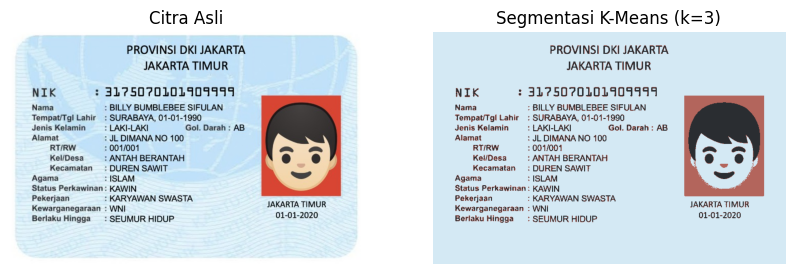

In [ ]:
from sklearn.cluster import KMeans

# Mengunduh sampel citra buah/bunga
!wget -nc https://raw.githubusercontent.com/opencv/opencv/master/samples/data/fruits.jpg -O /content/sample_data/images/lily.jpg
lily_img = cv.imread('/content/drive/MyDrive/Colab Notebooks/semester 5/PCVk/foto /ktp tumbal.jpeg')
lily_rgb = cv.cvtColor(lily_img, cv.COLOR_BGR2RGB)

pixel_vals = lily_rgb.reshape((-1, 3))
pixel_vals = np.float32(pixel_vals)

k = 3
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
kmeans.fit(pixel_vals)

centers = np.uint8(kmeans.cluster_centers_)
labels = kmeans.labels_

segmented_data = centers[labels.flatten()]
segmented_image = segmented_data.reshape(lily_rgb.shape)

# Tampilkan hasil
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(lily_rgb)
plt.title('Citra Asli')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(segmented_image)
plt.title(f'Segmentasi K-Means (k={k})')
plt.axis('off')
plt.show()